#### ClusterCentroids for removing overlapping in data

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../HeartDisease_cleaned.csv")


In [16]:
df.head()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST
0,40,1,140,289,0,172,0,0.0,3,0,0,1,0,0,0,1,0
1,49,0,160,180,0,156,0,1.0,2,1,0,0,1,0,0,1,0
2,37,1,130,283,0,98,0,0.0,3,0,0,1,0,0,0,0,1
3,48,0,138,214,0,108,1,1.5,2,1,1,0,0,0,0,1,0
4,54,1,150,195,0,122,0,0.0,3,0,0,0,1,0,0,1,0


<Axes: xlabel='Age', ylabel='MaxHR'>

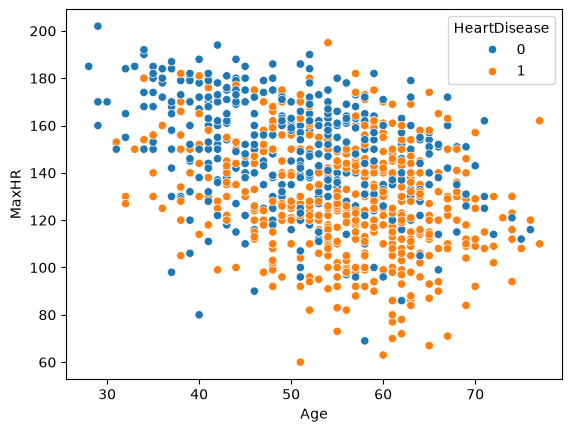

In [17]:
# Now let's take a particularly nasty overlap. Here.
sns.scatterplot(df, x="Age", y="MaxHR", hue="HeartDisease")

# In real life, does this overlap seem feasible? Probably.
# There's always some overlap (especially in health diagnosis data,
# like this heart disease data).

# But say this didn't reflect reality and there's some reason to 
# fix the overlap (to which there are many)...

#### ClusterCentroids

In [18]:
from imblearn.under_sampling import ClusterCentroids

# need to remove NaNs before ClusterCentroids
df = df.dropna()

# X y split to prevent data leakage
X = df.drop(columns="HeartDisease", axis=1)
y = df["HeartDisease"]

strategy = {
    1: 410,
    0: 410
}

cc = ClusterCentroids(
    sampling_strategy=strategy,
    random_state=31555
)

X_resampled, y_resampled = cc.fit_resample(X, y)

# Make a new copy (so we don't have trouble with dependency)
df_resampled = X_resampled.copy()

# Add y back into the X rows
df_resampled["HeartDisease"] = y_resampled
df_resampled

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,HeartDisease
0,54,0,160,312,0,130,0,0.0,3,0,1,0,0,0,1,0,0
1,49,0,130,207,0,135,0,0.0,3,0,0,1,0,0,0,1,0
2,60,1,120,0,0,133,1,2.0,3,1,0,0,0,0,1,0,0
3,47,1,138,257,0,156,0,0.0,3,0,0,1,0,1,0,0,0
4,62,0,140,394,0,157,0,1.2,2,1,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
815,47,1,155,0,0,118,1,1.0,2,0,0,1,0,0,1,0,1
816,69,1,140,208,0,140,1,2.0,2,1,0,0,0,0,0,1,1
817,53,1,130,0,0,135,1,1.0,2,1,0,0,0,1,0,0,1
818,51,1,130,0,1,170,0,-0.7,3,1,0,0,0,0,1,0,1


Text(0.5, 1.0, 'Original Data')

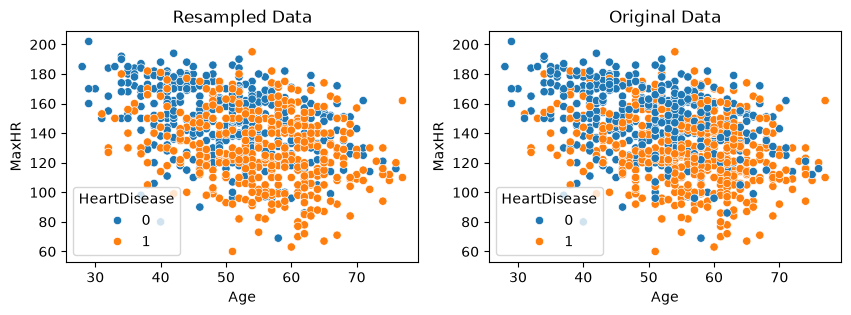

In [ ]:
# Let's look at it again. How did it perform?
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.scatterplot(df, x="Age", y="MaxHR", hue="HeartDisease", ax=axes[1])    
sns.scatterplot(df_resampled, x="Age", y="MaxHR", hue="HeartDisease", ax=axes[0])
axes[0].set_title("Resampled Data")
axes[1].set_title("Original Data")
# Not bad too, but still a little underwhelming.

# Not bad too, but still a little underwhelming.

# There is still a lot of overlap between the two classes in the middle of the plot.
# That makes sense, since ClusterCentroids only reduces the number of majority rows
# and does not move the classes apart.

In [20]:
# But let's do a sanity check. How many rows did it get rid of?
print(df.shape)
print(df_resampled.shape)

(918, 17)
(820, 17)
